# Segmentación de inundaciones con U-Net

El objetivo es entrenar una **U-Net** para segmentar zonas inundadas en imágenes, usando pares imagen-máscara.

La segmentación semántica asigna una clase a cada píxel. En este caso se trabaja con dos clases:

- **0**: fondo / zona no inundada.
- **1**: zona inundada.

Además del entrenamiento, el notebook guarda resultados intermedios para facilitar la revisión del proceso: configuración, métricas, checkpoints, predicciones y visualizaciones.

## 1. Importación de librerías

Se utilizan librerías de PyTorch para construir y entrenar la red neuronal, `torchvision` para transformaciones de imagen, `PIL` para lectura de archivos y `matplotlib` para visualizar resultados.

In [1]:
import os
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import PIL.Image
import torch
import torch.nn.functional as F
import torchvision
from matplotlib import pyplot as plt
from torch.optim.lr_scheduler import StepLR
from sklearn.model_selection import train_test_split
from torchvision.transforms import v2      # [MEJORA A4] data augmentation
from torchvision import tv_tensors          # [MEJORA A4] para transformar imagen y máscara a la vez   # [MEJORA 1] división entrenamiento / test

## 2. Configuración general

Centralizamos los parámetros principales para que sea sencillo modificar el experimento sin tener que buscar valores dispersos por el notebook.

> Nota: si se dispone de GPU CUDA con memoria suficiente, se puede activar `USAR_GPU = True`. En equipos Apple Silicon se puede usar `mps` si está disponible.

In [2]:
# Rutas de entrada
RUTA_IMAGENES = Path('./data/Image')
RUTA_MASCARAS = Path('./data/Mask')

# Carpeta de salida para resultados intermedios
# [MEJORA D] Una carpeta por etapa para no sobrescribir los resultados anteriores
NOMBRE_EXPERIMENTO = 'A1_A4_C1_evolucion'
RUTA_RESULTADOS = Path('./resultados_unet_practica') / NOMBRE_EXPERIMENTO
RUTA_CHECKPOINTS = RUTA_RESULTADOS / 'checkpoints'
RUTA_PREDICCIONES = RUTA_RESULTADOS / 'predicciones'
RUTA_FIGURAS = RUTA_RESULTADOS / 'figuras'

for carpeta in [RUTA_RESULTADOS, RUTA_CHECKPOINTS, RUTA_PREDICCIONES, RUTA_FIGURAS]:
    carpeta.mkdir(parents=True, exist_ok=True)

# Hiperparámetros
TAMANIO_IMAGEN = 100
BATCH_SIZE = 16
EPOCHS = 40                # [MEJORA A1] antes 20
LEARNING_RATE = 0.001      # [MEJORA A1] antes 0.01
GAMMA_SCHEDULER = 0.5
STEP_SIZE_SCHEDULER = 10   # [MEJORA A1] antes 1: ahora el lr se reduce a la mitad cada 10 épocas, no en cada época
USAR_GPU = True
USAR_MPS = False
SEMILLA = 42

# Selección de dispositivo
if USAR_GPU and torch.cuda.is_available():
    device = torch.device('cuda')
elif USAR_MPS and torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')

random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)

print(f'Dispositivo seleccionado: {device}')

Dispositivo seleccionado: cuda


## 3. Guardado de la configuración del experimento

Guardar la configuración permite reproducir el entrenamiento más adelante y saber exactamente qué parámetros se usaron.

In [3]:
config = {
    'ruta_imagenes': str(RUTA_IMAGENES),
    'ruta_mascaras': str(RUTA_MASCARAS),
    'tamanio_imagen': TAMANIO_IMAGEN,
    'batch_size': BATCH_SIZE,
    'epochs': EPOCHS,
    'learning_rate': LEARNING_RATE,
    'gamma_scheduler': GAMMA_SCHEDULER,
    'step_size_scheduler': STEP_SIZE_SCHEDULER,
    'device': str(device),
    'semilla': SEMILLA,
}

with open(RUTA_RESULTADOS / 'configuracion.json', 'w', encoding='utf-8') as f:
    json.dump(config, f, indent=4, ensure_ascii=False)

config

{'ruta_imagenes': 'data\\Image',
 'ruta_mascaras': 'data\\Mask',
 'tamanio_imagen': 100,
 'batch_size': 16,
 'epochs': 40,
 'learning_rate': 0.001,
 'gamma_scheduler': 0.5,
 'step_size_scheduler': 10,
 'device': 'cuda',
 'semilla': 42}

## 4. Bloques básicos de la U-Net

La U-Net combina dos caminos:

1. **Encoder o camino de contracción**: reduce la resolución espacial y aprende características cada vez más abstractas.
2. **Decoder o camino de expansión**: recupera la resolución original para producir una máscara píxel a píxel.

Las conexiones laterales, conocidas como **skip connections**, permiten conservar información espacial fina que podría perderse durante la reducción de resolución.

In [4]:
class DoubleConv(torch.nn.Module):
    """Bloque de dos convoluciones consecutivas.

    Cada convolución va seguida de Batch Normalization y ReLU. Este patrón es
    habitual en U-Net porque permite extraer características locales de forma
    progresiva.
    """

    def __init__(self, in_channels, out_channels, mid_channels=None):
        super().__init__()
        if not mid_channels:
            mid_channels = out_channels

        self.double_conv = torch.nn.Sequential(
            torch.nn.Conv2d(in_channels, mid_channels, kernel_size=3, padding=1, bias=False),
            torch.nn.BatchNorm2d(mid_channels),
            torch.nn.ReLU(inplace=True),
            torch.nn.Conv2d(mid_channels, out_channels, kernel_size=3, padding=1, bias=False),
            torch.nn.BatchNorm2d(out_channels),
            torch.nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.double_conv(x)


class Down(torch.nn.Module):
    """Bloque de reducción (downsample): MaxPool seguido de doble convolución."""

    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.maxpool_conv = torch.nn.Sequential(
            torch.nn.MaxPool2d(2),
            DoubleConv(in_channels, out_channels),
        )

    def forward(self, x):
        return self.maxpool_conv(x)


class Up(torch.nn.Module):
    """Bloque de expansión (upsample): aumenta la resolución y concatena la skip connection."""

    def __init__(self, in_channels, out_channels, bilinear=True):
        super().__init__()

        if bilinear: 
            # Con bilinear=True, el modelo aumenta el tamaño espacial de x1 duplicando alto y ancho, pero lo hace con una operación fija, 
            # no aprendida. La interpolación bilineal no aprende pesos. Simplemente calcula nuevos píxeles a partir de los vecinos, como
            # si agrandásemos una imagen 
            # Por tanto, aumenta la resolución de forma fija, no añade parámetros entrenables y suele ser más estable y simple

            self.up = torch.nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
            self.conv = DoubleConv(in_channels, out_channels, in_channels // 2)
        else:
            # ConvTranspose2d (convolución transpuesta 2D): aumenta la resolución aprendiendo filtros, añade parámetros entrenables
            # puede aprender mejor el upsampling, pero también puede introducir artefactos (patrones artificiales) si no se entrena adecuadamente, 
            # y suele ser más propenso a sobreajustar en datasets pequeños

            self.up = torch.nn.ConvTranspose2d(in_channels, in_channels // 2, kernel_size=2, stride=2)
            self.conv = DoubleConv(in_channels, out_channels)

    def forward(self, x1, x2):
        # x1 procede del decoder; x2 procede del encoder.
        x1 = self.up(x1)

        # Ajuste de tamaño por si hay pequeñas diferencias debidas a redondeos.
        diffY = x2.size()[2] - x1.size()[2] # tamaño en la dimensión de alto ya que la dimensión 0 es el batch, la 1 es el canal, 
                                            # la 2 es el alto y la 3 es el ancho
        diffX = x2.size()[3] - x1.size()[3] # tamaño en la dimensión de ancho

        x1 = F.pad(x1, [diffX // 2, diffX - diffX // 2,
                        diffY // 2, diffY - diffY // 2]) # Padding píxeles alrededor de x1 para que tenga el mismo alto y ancho que x2

        # Concatenación de características del encoder y del decoder.
        x = torch.cat([x2, x1], dim=1)
        return self.conv(x)


class OutConv(torch.nn.Module):
    """Capa final 1x1 que convierte las características en logits de clase."""

    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv = torch.nn.Conv2d(in_channels, out_channels, kernel_size=1)

    def forward(self, x):
        return self.conv(x)

## 5. Definición del modelo U-Net

La salida del modelo son **logits** con dos canales: uno para cada clase. Son “logits crudos”: valores numéricos de salida del modelo antes de convertirlos en probabilidades. Ejemplo de logits por clase:

fondo:     1.2

agua:      3.8

edificio: -0.7

No se aplica `softmax` dentro del modelo porque `CrossEntropyLoss` espera logits sin normalizar.

In [5]:
class UNet(torch.nn.Module):
    """Implementación de U-Net para segmentación binaria."""

    def __init__(self, n_channels, n_classes, bilinear=False): 
        
        '''
        bilinear=False para usar ConvTranspose2d, 
        bilinear=True para usar Upsample (interpolación bilineal)
        La interpolación bilineal es una forma de agrandar una imagen o un mapa de características calculando nuevos valores a partir de los 
        píxeles vecinos.
        '''
        
        super().__init__()
        self.n_channels = n_channels
        self.n_classes = n_classes
        self.bilinear = bilinear

        # Encoder
        self.inc = DoubleConv(n_channels, 64)
        self.down1 = Down(64, 128)
        self.down2 = Down(128, 256)
        self.down3 = Down(256, 512)

        factor = 2 if bilinear else 1
        self.down4 = Down(512, 1024 // factor)

        # Decoder
        self.up1 = Up(1024, 512 // factor, bilinear)
        self.up2 = Up(512, 256 // factor, bilinear)
        self.up3 = Up(256, 128 // factor, bilinear)
        self.up4 = Up(128, 64, bilinear)
        self.outc = OutConv(64, n_classes)

    def forward(self, x):
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        x5 = self.down4(x4)

        x = self.up1(x5, x4)
        x = self.up2(x, x3)
        x = self.up3(x, x2)
        x = self.up4(x, x1)
        logits = self.outc(x) # son “logits crudos”: valores numéricos de salida del modelo antes de convertirlos en probabilidades
        return logits

## 6. Funciones auxiliares

Estas funciones hacen el notebook más legible: cargan imágenes, calculan métricas y guardan visualizaciones intermedias.

In [6]:
def cargar_dataset(ruta_imagenes, ruta_mascaras, tamanio=100):
    """Carga imágenes JPG y máscaras PNG asociadas.

    Devuelve:
    - image_tensor: tensor [N, 3, H, W] con valores entre 0 y 1.
    - mask_tensor: tensor [N, H, W] con etiquetas enteras 0/1.
    - nombres_validos: nombres de archivo procesados correctamente.
    """
    imagenes = sorted([f for f in os.listdir(ruta_imagenes) if f.lower().endswith('.jpg')]) 
    # crea una lista ordenada con los nombres de los archivos .jpg que hay dentro de la carpeta ruta_imagenes

    image_tensors = []
    mask_tensors = []
    nombres_validos = []

    for nombre_imagen in imagenes:
        ruta_imagen = ruta_imagenes / nombre_imagen
        nombre_mascara = nombre_imagen.replace('.jpg', '.png')
        ruta_mascara = ruta_mascaras / nombre_mascara

        if not ruta_mascara.exists():
            print(f'Aviso: no se encontró máscara para {nombre_imagen}. Se omite.')
            continue

        imagen = PIL.Image.open(ruta_imagen).convert('RGB') # convierte a RGB la imagen
        imagen = torchvision.transforms.functional.pil_to_tensor(imagen) # convierte a tensor
        imagen = torchvision.transforms.functional.resize(imagen, (tamanio, tamanio)) 
        # redimensionamos a un tamaño fijo para que todas las imágenes tengan el mismo tamaño, lo cual es necesario para procesarlas en batch
        imagen = imagen.float() / 255.0 # normalizamos a [0, 1]

        if imagen.shape != (3, tamanio, tamanio):
            print(f'Aviso: formato inesperado en {nombre_imagen}: {imagen.shape}. Se omite.')
            continue

        mascara = PIL.Image.open(ruta_mascara).convert('L')
        mascara = torchvision.transforms.functional.pil_to_tensor(mascara)
        # Ese bloque prepara la máscara de segmentación para que tenga el tamaño correcto y esté en el formato que espera la red o 
        # la función de pérdida.
        
        mascara = torchvision.transforms.functional.resize(
            mascara,
            (tamanio, tamanio),
            interpolation=torchvision.transforms.InterpolationMode.NEAREST,
        )
        mascara = (mascara[0] > 0).long()

        # El resultado es mascara: (H, W) con valores: 0 o 1

        image_tensors.append(imagen.unsqueeze(0))
        mask_tensors.append(mascara.unsqueeze(0))
        nombres_validos.append(nombre_imagen)

    if not image_tensors:
        raise RuntimeError('No se cargó ninguna imagen válida. Revisa las rutas del dataset.')

    return torch.cat(image_tensors), torch.cat(mask_tensors), nombres_validos


def calcular_iou(pred_mask, true_mask, clase=1, eps=1e-7):
    """
    Calcula IoU/Jaccard para una clase concreta, normalmente la clase inundada
    Como 1 → zona inundada y 0 → fondo, la función suele calcular el IoU de la clase 1, es decir, la clase inundada.
    """
    
    pred_bin = pred_mask == clase # Convierte ambas máscaras en máscaras booleanas para la clase elegida.
    true_bin = true_mask == clase 

    interseccion = (pred_bin & true_bin).sum(dim=(1, 2)).float()
    union = (pred_bin | true_bin).sum(dim=(1, 2)).float()
    return ((interseccion + eps) / (union + eps)).mean().item()


def guardar_visualizacion(epoch, imagen, target, pred_mask, ruta_salida):
    
    """Guarda una figura con imagen original, máscara real, predicción y overlay."""
    imagen_np = imagen.detach().cpu().permute(1, 2, 0).numpy()
    target_np = target.detach().cpu().numpy()
    pred_np = pred_mask.detach().cpu().numpy()

    fig, axes = plt.subplots(1, 4, figsize=(14, 4))
    axes[0].imshow(imagen_np)
    axes[0].set_title('Imagen original')
    axes[0].axis('off')

    axes[1].imshow(target_np)
    axes[1].set_title('Máscara real')
    axes[1].axis('off')

    axes[2].imshow(pred_np)
    axes[2].set_title('Predicción')
    axes[2].axis('off')

    axes[3].imshow(imagen_np)
    axes[3].imshow(pred_np, alpha=0.35)
    axes[3].set_title('Overlay predicción')
    axes[3].axis('off')

    fig.suptitle(f'Resultados intermedios - época {epoch}')
    fig.tight_layout()
    fig.savefig(ruta_salida, dpi=150, bbox_inches='tight')
    plt.close(fig)

## 7. Carga y exploración inicial del dataset

Cada imagen tiene una máscara asociada. Las imágenes se normalizan a `[0, 1]`; las máscaras se convierten en etiquetas enteras `0` y `1`.

In [7]:
image_tensor, mask_tensor, nombres = cargar_dataset(RUTA_IMAGENES, RUTA_MASCARAS, TAMANIO_IMAGEN)

print('Imágenes:', image_tensor.shape)
print('Máscaras:', mask_tensor.shape)
print('Número de muestras:', len(nombres))

# Guardamos los nombres de las imágenes procesadas para trazabilidad.
with open(RUTA_RESULTADOS / 'imagenes_procesadas.txt', 'w', encoding='utf-8') as f:
    for nombre in nombres:
        f.write(nombre + '\n')   # [MEJORA D] faltaba el salto de línea

Imágenes: torch.Size([290, 3, 100, 100])
Máscaras: torch.Size([290, 100, 100])
Número de muestras: 290


## 8. Visualización de una muestra

Antes de entrenar conviene comprobar que las imágenes y las máscaras están bien alineadas.

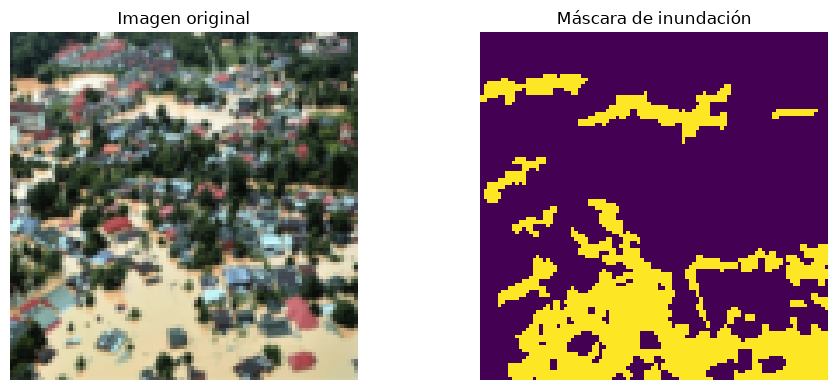

In [8]:
indice = 0
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image_tensor[indice].permute(1, 2, 0))
plt.title('Imagen original')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(mask_tensor[indice])
plt.title('Máscara de inundación')
plt.axis('off')

plt.tight_layout()
plt.savefig(RUTA_FIGURAS / 'muestra_dataset.png', dpi=150, bbox_inches='tight')
plt.show()

## 9. Preparación del entrenamiento

Se crea un `TensorDataset` con imagen y máscara juntas. Esto evita desalineaciones entre dos `DataLoader` separados.

La función de pérdida es `CrossEntropyLoss`, adecuada para segmentación multiclase cuando la máscara contiene índices de clase.

### Data augmentation [MEJORA A4]

Con solo 232 imágenes de entrenamiento, la red puede acabar memorizándolas. El *data augmentation* genera en cada época versiones ligeramente distintas de cada imagen:

- Volteo horizontal y vertical (en una foto aérea no hay un "arriba" fijo).
- Rotación de hasta ±15°.
- Cambios de brillo, contraste, saturación y tono (distintas condiciones de luz).

En segmentación, las transformaciones geométricas deben aplicarse **exactamente igual** a la imagen y a su máscara. Al envolver la máscara en `tv_tensors.Mask`, `v2.Compose` le aplica el mismo volteo y rotación que a la imagen, y no le aplica los cambios de color. El augmentation se usa **solo en entrenamiento**: el test se evalúa con las imágenes originales.

In [9]:
# [MEJORA A4] Transformaciones aleatorias de data augmentation
transform_augmentation = v2.Compose([
    v2.RandomHorizontalFlip(p=0.5),
    v2.RandomVerticalFlip(p=0.5),
    v2.RandomRotation(degrees=15),
    v2.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.02),
])


class DatasetInundaciones(torch.utils.data.Dataset):
    """Devuelve pares (imagen, máscara) aplicando el augmentation a ambos a la vez."""

    def __init__(self, imagenes, mascaras, transform=None):
        self.imagenes = imagenes
        self.mascaras = mascaras
        self.transform = transform

    def __len__(self):
        return len(self.imagenes)

    def __getitem__(self, i):
        imagen, mascara = self.imagenes[i], self.mascaras[i]
        if self.transform is not None:
            # tv_tensors indica qué es imagen y qué es máscara: misma geometría, color solo en la imagen
            imagen, mascara = self.transform(tv_tensors.Image(imagen), tv_tensors.Mask(mascara))
        return imagen.as_subclass(torch.Tensor), mascara.as_subclass(torch.Tensor)

In [10]:
# [4] División en entrenamiento (80 %) y test (20 %)
(imagenes_train, imagenes_test,
 mascaras_train, mascaras_test,
 nombres_train, nombres_test) = train_test_split(
    image_tensor, mask_tensor, nombres, test_size=0.2, random_state=SEMILLA)

print(f'Entrenamiento: {len(imagenes_train)} imágenes | Test: {len(imagenes_test)} imágenes')

# [MEJORA A4] El conjunto de entrenamiento aplica data augmentation; test no
dataset_train = DatasetInundaciones(imagenes_train, mascaras_train, transform_augmentation)
dataset_train_eval = torch.utils.data.TensorDataset(imagenes_train, mascaras_train)   # sin augmentation, solo para medir
dataset_test = torch.utils.data.TensorDataset(imagenes_test, mascaras_test)

dataloader_train = torch.utils.data.DataLoader(dataset_train, batch_size=BATCH_SIZE, shuffle=True)
dataloader_train_eval = torch.utils.data.DataLoader(dataset_train_eval, batch_size=BATCH_SIZE, shuffle=False)   # [MEJORA A4]
dataloader_test = torch.utils.data.DataLoader(dataset_test, batch_size=BATCH_SIZE, shuffle=False)

unet = UNet(n_channels=3, n_classes=2).to(device)
optimizer = torch.optim.Adam(unet.parameters(), lr=LEARNING_RATE)
scheduler = StepLR(optimizer=optimizer, step_size=STEP_SIZE_SCHEDULER, gamma=GAMMA_SCHEDULER)
criterion = torch.nn.CrossEntropyLoss()
# aplica log_softmax(logits)y después calcula la pérdida con la clase correcta.

metricas = []
print(unet)

Entrenamiento: 232 imágenes | Test: 58 imágenes
UNet(
  (inc): DoubleConv(
    (double_conv): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (down1): Down(
    (maxpool_conv): Sequential(
      (0): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (1): DoubleConv(
        (double_conv): Sequential(
          (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
          (2): ReLU(inplace=True)
          (3): 

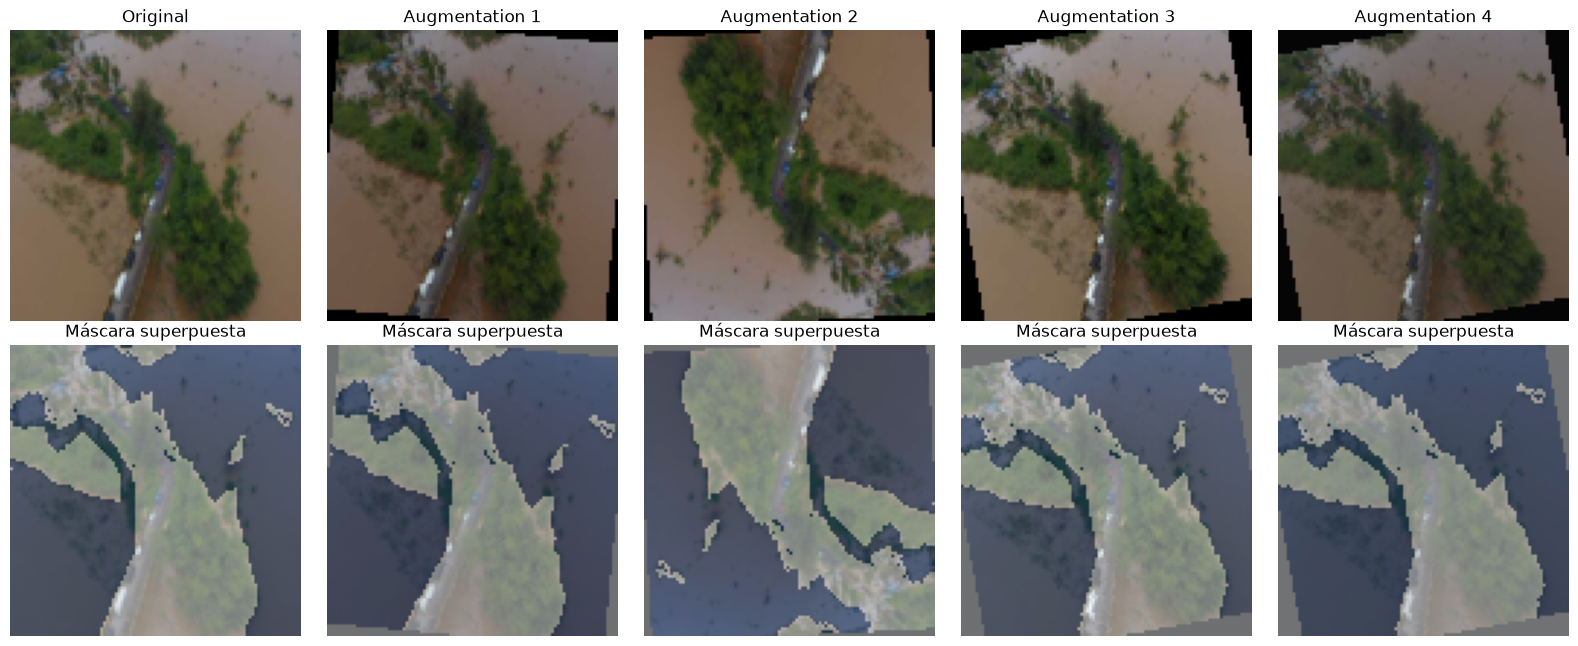

In [11]:
# [MEJORA A4] Comprobación visual: una imagen de entrenamiento y 4 versiones con augmentation.
# Fila superior: imagen; fila inferior: máscara superpuesta (debe seguir encajando con el agua).
muestras = [(imagenes_train[0], mascaras_train[0])] + [dataset_train[0] for _ in range(4)]

fig, axes = plt.subplots(2, 5, figsize=(16, 6.5))
for col, (img, msk) in enumerate(muestras):
    axes[0, col].imshow(img.permute(1, 2, 0).clamp(0, 1))
    axes[0, col].set_title('Original' if col == 0 else f'Augmentation {col}')
    axes[1, col].imshow(img.permute(1, 2, 0).clamp(0, 1))
    axes[1, col].imshow(msk, alpha=0.45, cmap='Blues', vmin=0, vmax=1)
    axes[1, col].set_title('Máscara superpuesta')
    axes[0, col].axis('off')
    axes[1, col].axis('off')
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / 'ejemplos_augmentation.png', dpi=150, bbox_inches='tight')
plt.show()

## 10. Entrenamiento

En cada época se realiza:

1. Predicción de la máscara.
2. Cálculo de la pérdida.
3. Retropropagación.
4. Actualización de pesos.
5. Evaluación con IoU/Jaccard.
6. Guardado de resultados intermedios.

In [12]:
# [MEJORA C1] Predicción de una imagen de TEST fija en cada época, para ver cómo evoluciona
evolucion = {}

for epoch in range(1, EPOCHS + 1):
    unet.train()
    running_loss = 0.0

    for images_batch, masks_batch in dataloader_train:
        images_batch = images_batch.to(device)
        masks_batch = masks_batch.to(device)

        optimizer.zero_grad()
        logits = unet(images_batch)
        loss = criterion(logits, masks_batch)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    # Evaluación simple sobre el mismo conjunto de entrenamiento.
    unet.eval()
    iou_epoch = []
    with torch.no_grad():
        for images_batch, masks_batch in dataloader_train_eval:   # [MEJORA A4] imágenes de entrenamiento SIN augmentation
            images_batch = images_batch.to(device)
            masks_batch = masks_batch.to(device)

            logits = unet(images_batch)
            pred_mask = torch.argmax(logits, dim=1) # para cada píxel, elegir la clase con mayor logit.
            iou_epoch.append(calcular_iou(pred_mask.cpu(), masks_batch.cpu(), clase=1))

    mean_iou = float(np.mean(iou_epoch))

    # [MEJORA 2] Evaluación sobre el conjunto de test (modo inferencia, sin gradientes)
    test_loss = 0.0
    iou_test_epoch = []
    with torch.no_grad():
        for images_batch, masks_batch in dataloader_test:
            images_batch = images_batch.to(device)
            masks_batch = masks_batch.to(device)

            logits = unet(images_batch)
            test_loss += criterion(logits, masks_batch).item()
            pred_mask = torch.argmax(logits, dim=1)
            iou_test_epoch.append(calcular_iou(pred_mask.cpu(), masks_batch.cpu(), clase=1))

    mean_iou_test = float(np.mean(iou_test_epoch))
    lr_actual = optimizer.param_groups[0]['lr'] # leer el learning rate actual que está usando el optimizador.

    metricas.append({
        'epoch': epoch,
        'loss': running_loss,
        'iou_clase_inundada': mean_iou,
        'loss_test': test_loss,           # [MEJORA 2]
        'iou_test': mean_iou_test,        # [MEJORA 2]
        'learning_rate': lr_actual,
    })

    print(f'Época {epoch:02d}/{EPOCHS} | pérdida train={running_loss:.4f} test={test_loss:.4f} | '
          f'IoU train={mean_iou:.4f} test={mean_iou_test:.4f} | lr={lr_actual:.6f}')   # [MEJORA 2]

    # Guardado de una predicción intermedia para inspección visual.
    # [MEJORA C1] Se usa una imagen de TEST (antes image_tensor[0], que es de entrenamiento)
    with torch.no_grad():
        muestra_img = imagenes_test[0:1].to(device)
        logits_muestra = unet(muestra_img)
        pred_muestra = torch.argmax(logits_muestra, dim=1)[0]

    evolucion[epoch] = pred_muestra.cpu() 
    torch.save(pred_muestra.cpu(), RUTA_PREDICCIONES / f'prediccion_epoch_{epoch:03d}.pt')

    guardar_visualizacion(
        epoch,
        imagenes_test[0],
        mascaras_test[0],
        pred_muestra.cpu(),
        RUTA_FIGURAS / f'visualizacion_epoch_{epoch:03d}.png',
    )

    scheduler.step()

# [MEJORA D] Un único checkpoint al final del entrenamiento
# (antes se guardaba uno de ~370 MB en cada época: unos 7,5 GB por ejecución)
checkpoint = {
    'epoch': EPOCHS,
    'model_state_dict': unet.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'scheduler_state_dict': scheduler.state_dict(),
    'metricas': metricas,
    'config': config,
}
torch.save(checkpoint, RUTA_CHECKPOINTS / 'unet_flood_final.pt')

# Guardado de métricas al terminar.
df_metricas = pd.DataFrame(metricas)
df_metricas.to_csv(RUTA_RESULTADOS / 'metricas_entrenamiento.csv', index=False)
df_metricas.tail()

Época 01/40 | pérdida train=6.8562 test=25.8059 | IoU train=0.4168 test=0.3982 | lr=0.001000
Época 02/40 | pérdida train=6.1757 test=4.6598 | IoU train=0.4426 test=0.4249 | lr=0.001000
Época 03/40 | pérdida train=6.1102 test=2.5006 | IoU train=0.5692 test=0.5475 | lr=0.001000
Época 04/40 | pérdida train=5.8043 test=1.7577 | IoU train=0.6303 test=0.6291 | lr=0.001000
Época 05/40 | pérdida train=5.6066 test=1.7259 | IoU train=0.5341 test=0.5216 | lr=0.001000
Época 06/40 | pérdida train=5.4232 test=1.6390 | IoU train=0.6361 test=0.6202 | lr=0.001000
Época 07/40 | pérdida train=5.3310 test=1.6046 | IoU train=0.6438 test=0.6439 | lr=0.001000
Época 08/40 | pérdida train=5.2245 test=1.5625 | IoU train=0.6467 test=0.6337 | lr=0.001000
Época 09/40 | pérdida train=5.2127 test=2.0390 | IoU train=0.4511 test=0.4129 | lr=0.001000
Época 10/40 | pérdida train=5.0076 test=1.6543 | IoU train=0.5934 test=0.5766 | lr=0.001000
Época 11/40 | pérdida train=5.0458 test=1.4433 | IoU train=0.6940 test=0.6736 |

,epoch,loss,iou_clase_inundada,loss_test,iou_test,learning_rate
35,36,4.154623,0.725593,1.289144,0.700281,0.000125
36,37,4.032795,0.731043,1.333864,0.709030,0.000125
37,38,4.068230,0.715015,1.339121,0.682772,0.000125
38,39,4.034472,0.730940,1.277249,0.709931,0.000125
39,40,4.067979,0.731300,1.322257,0.705814,0.000125


## 11. Curvas de entrenamiento

Las curvas ayudan a diagnosticar si el modelo está aprendiendo y si la tasa de aprendizaje resulta demasiado agresiva o demasiado baja.

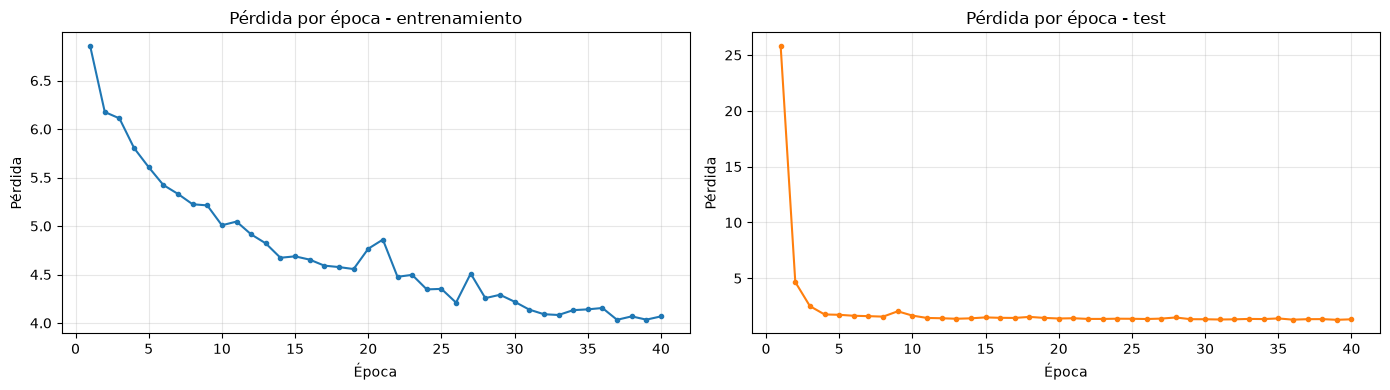

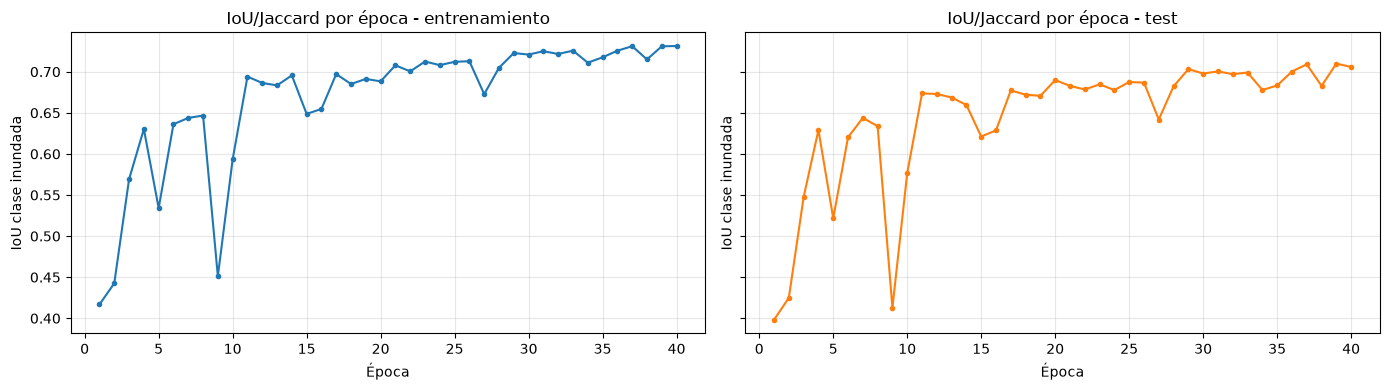

In [13]:
# [MEJORA 2] Curvas de entrenamiento y test, una al lado de la otra
df_metricas = pd.read_csv(RUTA_RESULTADOS / 'metricas_entrenamiento.csv')

# Pérdida por época
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(df_metricas['epoch'], df_metricas['loss'], marker='o', markersize=3)
axes[0].set_title('Pérdida por época - entrenamiento')
axes[1].plot(df_metricas['epoch'], df_metricas['loss_test'], marker='o', markersize=3, color='tab:orange')
axes[1].set_title('Pérdida por época - test')
for ax in axes:
    ax.set_xlabel('Época')
    ax.set_ylabel('Pérdida')
    ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / 'curva_perdida.png', dpi=150, bbox_inches='tight')
plt.show()

# IoU por época (mismo eje vertical en los dos paneles para poder compararlos)
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
axes[0].plot(df_metricas['epoch'], df_metricas['iou_clase_inundada'], marker='o', markersize=3)
axes[0].set_title('IoU/Jaccard por época - entrenamiento')
axes[1].plot(df_metricas['epoch'], df_metricas['iou_test'], marker='o', markersize=3, color='tab:orange')
axes[1].set_title('IoU/Jaccard por época - test')
for ax in axes:
    ax.set_xlabel('Época')
    ax.set_ylabel('IoU clase inundada')
    ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / 'curva_iou.png', dpi=150, bbox_inches='tight')
plt.show()


## 11b. Evolución de la predicción durante el entrenamiento [MEJORA C1]

La misma imagen de **test** vista en distintas épocas del entrenamiento. Al principio la máscara predicha es casi ruido y, época a época, va convergiendo hacia la máscara real. Sobre cada predicción se indica su índice de Jaccard con la máscara real de esa imagen.

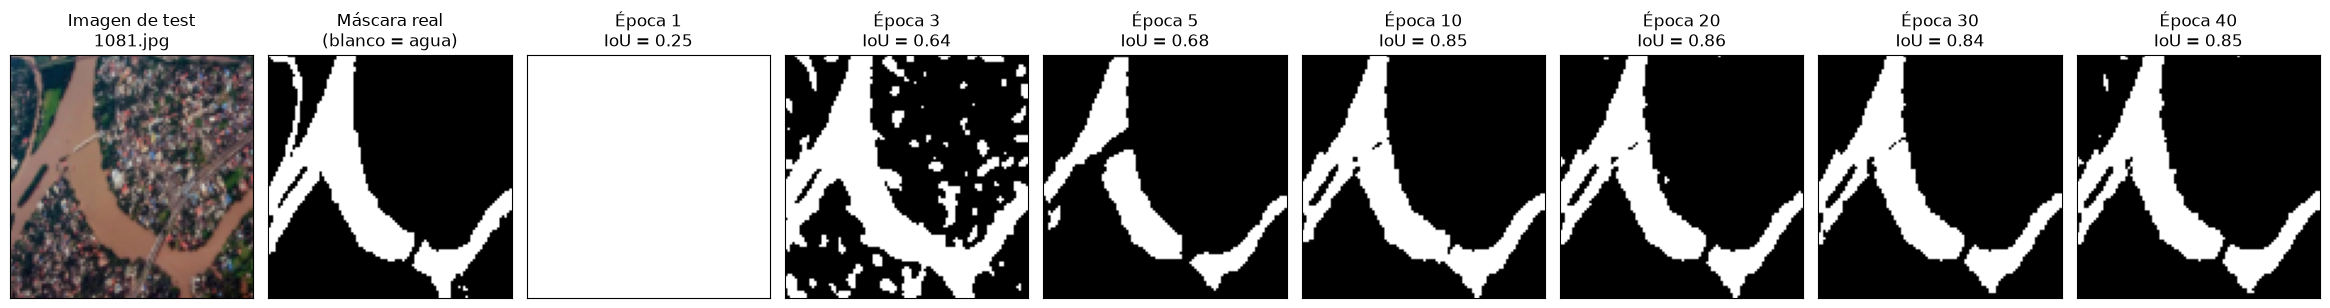

In [14]:
# [MEJORA C1] Figura de evolución: imagen, máscara real y predicción en varias épocas
EPOCAS_MOSTRAR = [e for e in [1, 3, 5, 10, 20, 30, 40] if e in evolucion]

paneles = len(EPOCAS_MOSTRAR) + 2
fig, axes = plt.subplots(1, paneles, figsize=(2.6 * paneles, 3.3))

axes[0].imshow(imagenes_test[0].permute(1, 2, 0))
axes[0].set_title(f'Imagen de test\n{nombres_test[0]}')
axes[1].imshow(mascaras_test[0], cmap='gray', vmin=0, vmax=1)
axes[1].set_title('Máscara real\n(blanco = agua)')

for ax, epoca in zip(axes[2:], EPOCAS_MOSTRAR):
    pred = evolucion[epoca]
    iou = calcular_iou(pred.unsqueeze(0), mascaras_test[0:1], clase=1)
    ax.imshow(pred, cmap='gray', vmin=0, vmax=1)
    ax.set_title(f'Época {epoca}\nIoU = {iou:.2f}')

for ax in axes:
    ax.set_xticks([])   # sin ejes, pero con marco para distinguir los paneles
    ax.set_yticks([])

fig.tight_layout()
fig.savefig(RUTA_FIGURAS / 'evolucion_prediccion.png', dpi=150, bbox_inches='tight')
plt.show()

## 12. Visualización final

Mostramos una predicción final sobre una imagen del conjunto de **test**, que la red no ha visto durante el entrenamiento. [MEJORA C1: antes se usaba una imagen de entrenamiento]

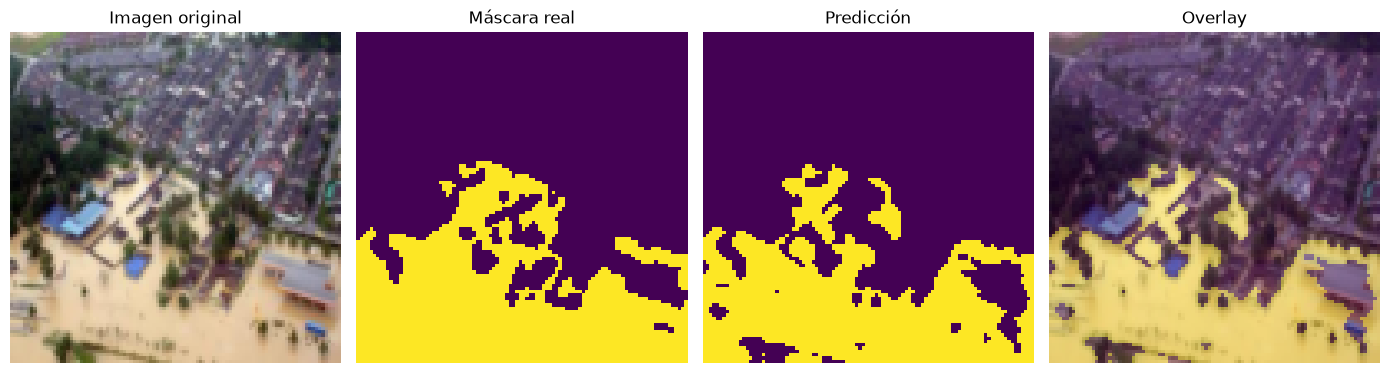

In [15]:
unet.eval()
indice = 1   # [MEJORA C1] segunda imagen de test (la primera ya se usa en la figura de evolución)

with torch.no_grad():
    imagen = imagenes_test[indice:indice+1].to(device)
    logits = unet(imagen)
    pred = torch.argmax(logits, dim=1)[0].cpu()

ruta_final = RUTA_FIGURAS / 'comparacion_final.png'
guardar_visualizacion(EPOCHS, imagenes_test[indice], mascaras_test[indice], pred, ruta_final)

img_np = imagenes_test[indice].permute(1, 2, 0).numpy()
mask_np = mascaras_test[indice].numpy()
pred_np = pred.numpy()

plt.figure(figsize=(14, 4))

plt.subplot(1, 4, 1)
plt.imshow(img_np)
plt.title('Imagen original')
plt.axis('off')

plt.subplot(1, 4, 2)
plt.imshow(mask_np)
plt.title('Máscara real')
plt.axis('off')

plt.subplot(1, 4, 3)
plt.imshow(pred_np)
plt.title('Predicción')
plt.axis('off')

plt.subplot(1, 4, 4)
plt.imshow(img_np)
plt.imshow(pred_np, alpha=0.35)
plt.title('Overlay')
plt.axis('off')

plt.tight_layout()
plt.show()

## 12b. Análisis de errores: mejores y peores predicciones en test [MEJORA C2]

El índice de Jaccard global resume el rendimiento en un solo número, pero no dice **dónde** acierta y dónde falla la red. Para verlo, se calcula el IoU de cada imagen de test por separado y se muestran las 3 imágenes con peor resultado y las 3 con mejor. En clase se observó que el modelo confundía zonas como el cielo o el horizonte con agua: este análisis permite comprobar qué tipo de imágenes le resultan más difíciles.

Se usa el modelo final ya entrenado, por lo que esta celda no requiere volver a entrenar.

IoU por imagen en test: media 0.715 | mediana 0.738 | mínimo 0.130 | máximo 0.932


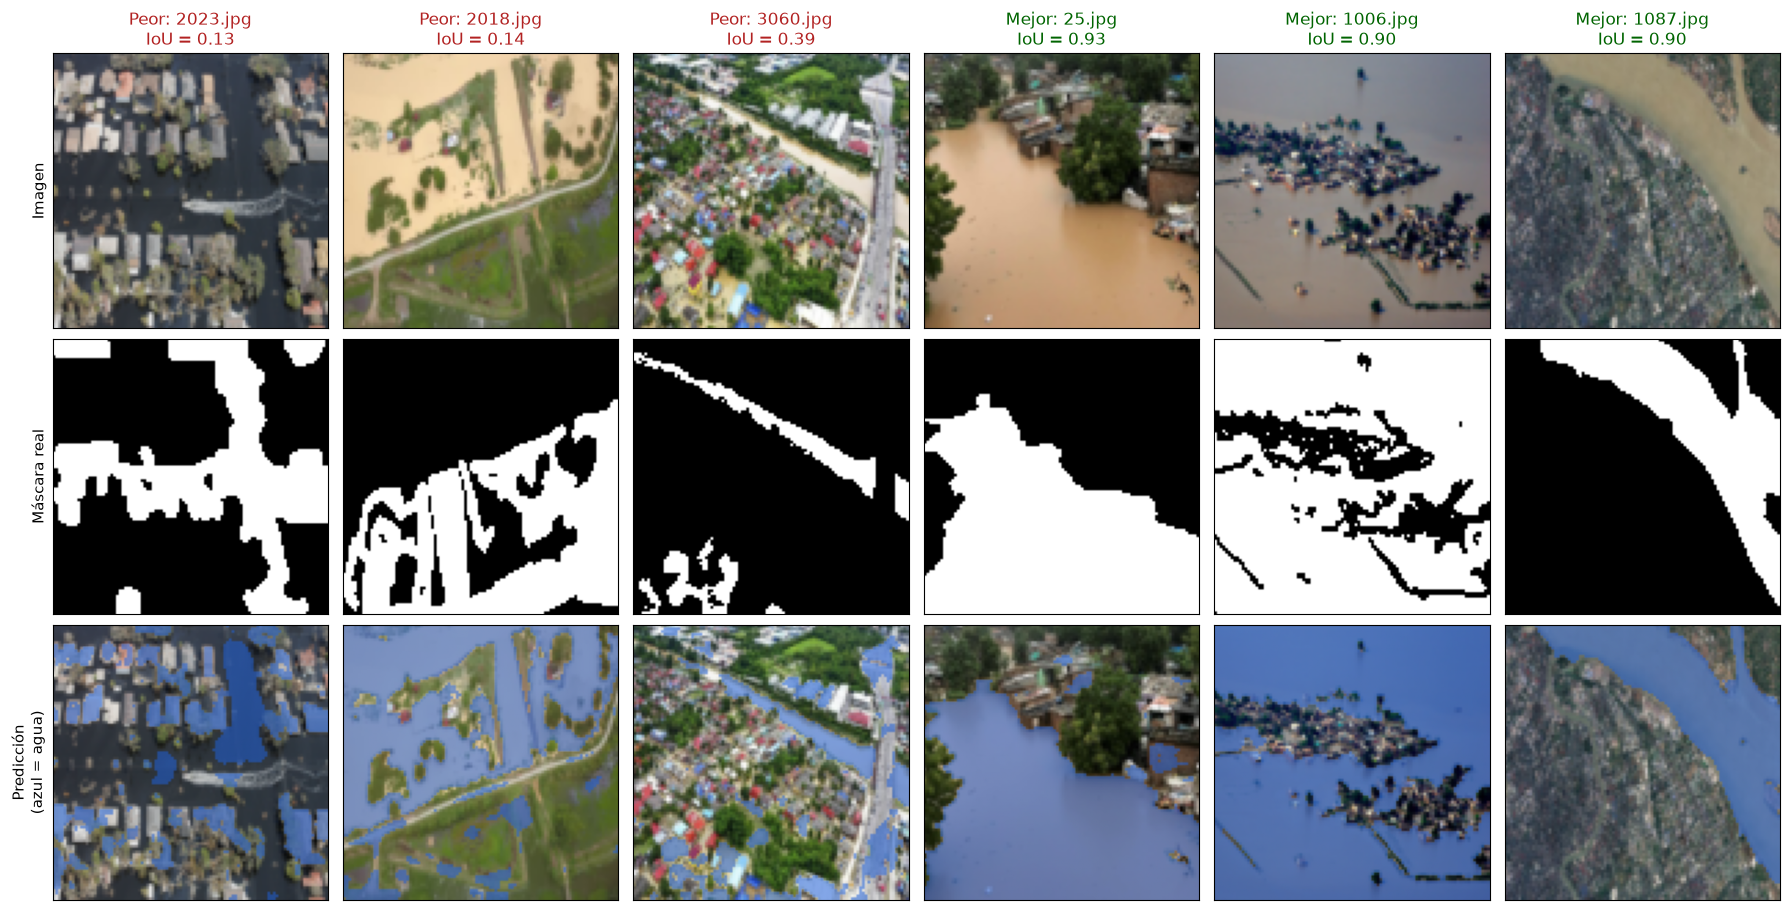

In [16]:
# [MEJORA C2] IoU de cada imagen de test con el modelo final
import matplotlib
unet.eval()
with torch.no_grad():
    preds_test = torch.cat([
        torch.argmax(unet(imagenes_test[i:i + BATCH_SIZE].to(device)), dim=1).cpu()
        for i in range(0, len(imagenes_test), BATCH_SIZE)
    ])

iou_por_imagen = np.array([
    calcular_iou(preds_test[i:i + 1], mascaras_test[i:i + 1], clase=1)
    for i in range(len(imagenes_test))
])

df_iou_imagen = pd.DataFrame({'imagen': nombres_test, 'iou': iou_por_imagen}).sort_values('iou')
df_iou_imagen.to_csv(RUTA_RESULTADOS / 'iou_por_imagen_test.csv', index=False)
print(f'IoU por imagen en test: media {iou_por_imagen.mean():.3f} | mediana {np.median(iou_por_imagen):.3f} | '
      f'mínimo {iou_por_imagen.min():.3f} | máximo {iou_por_imagen.max():.3f}')

# 3 peores y 3 mejores, en columnas; filas: imagen, máscara real y predicción superpuesta
orden = np.argsort(iou_por_imagen)
seleccion = [('Peor', i) for i in orden[:3]] + [('Mejor', i) for i in orden[::-1][:3]]

fig, axes = plt.subplots(3, len(seleccion), figsize=(3.0 * len(seleccion), 9.2))
for col, (tipo, i) in enumerate(seleccion):
    img = imagenes_test[i].permute(1, 2, 0)
    color = 'firebrick' if tipo == 'Peor' else 'darkgreen'

    axes[0, col].imshow(img)
    axes[0, col].set_title(f'{tipo}: {nombres_test[i]}\nIoU = {iou_por_imagen[i]:.2f}', color=color)
    axes[1, col].imshow(mascaras_test[i], cmap='gray', vmin=0, vmax=1)
    axes[2, col].imshow(img)
    agua_pred = np.ma.masked_where(preds_test[i].numpy() == 0, preds_test[i].numpy())   # solo se pinta el agua
    axes[2, col].imshow(agua_pred, cmap=matplotlib.colors.ListedColormap(['#1f5fd6']), alpha=0.55)

axes[1, 0].set_ylabel('Máscara real', fontsize=11)
axes[2, 0].set_ylabel('Predicción\n(azul = agua)', fontsize=11)
axes[0, 0].set_ylabel('Imagen', fontsize=11)
for ax in axes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])

fig.tight_layout()
fig.savefig(RUTA_FIGURAS / 'mejores_peores_test.png', dpi=150, bbox_inches='tight')
plt.show()

## 12c. ¿Dónde se equivoca la red? [MEJORA C3]

El IoU dice **cuánto** falla la red, pero no **dónde**. Esta celda compara, píxel a píxel, la predicción con la máscara real en las 58 imágenes de test y clasifica cada píxel en una de cuatro "cajas":

| | La máscara dice **agua** | La máscara dice **fondo** |
|---|---|---|
| **La red dice agua** | ✅ Agua acertada | ❌ **Falsa alarma**: se inventa agua |
| **La red dice fondo** | ❌ **Agua perdida**: se le escapa agua | ✅ Fondo acertado |

Con eso responde a cuatro preguntas sencillas:

1. **¿Cuánto falla?** Porcentaje de píxeles mal y qué tipo de error domina.
2. **¿Bordes o interior?** Si los fallos están en el contorno del agua (dibuja mal la orilla) o en zonas enteras (confunde una cosa con otra).
3. **¿En qué zona de la foto?** Arriba, centro o abajo. En clase se vio que la red confunde el cielo o el horizonte con agua, y suelen estar en la parte de arriba.
4. **¿Pocas imágenes o todas?** Si unas pocas fotos difíciles acumulan casi todos los errores.

Al final imprime un resumen en lenguaje llano y guarda la figura `analisis_errores_test.png` y la tabla `errores_por_imagen_test.csv`.

No hace falta volver a entrenar: usa el modelo final que ya está en memoria.

1) ¿CUÁNTO FALLA?
   Píxeles de test: 580,000  ->  mal clasificados: 75,033 (12.9 %)
   · Falsas alarmas (ve agua donde no hay): 51 % de los errores
   · Agua perdida  (no ve agua que sí hay): 49 % de los errores

2) ¿BORDES O INTERIOR?
   Las franjas de borde ocupan el 30 % de la imagen, pero concentran el 56 % de los errores.

3) ¿EN QUÉ ZONA DE LA FOTO?  (% de píxeles de esa zona que están mal)
   Arriba   -> falsas alarmas  7.2 % | agua perdida  6.9 %
   Centro   -> falsas alarmas  6.3 % | agua perdida  7.1 %
   Abajo    -> falsas alarmas  6.2 % | agua perdida  5.2 %

4) ¿POCAS IMÁGENES O TODAS?
   Las 6 imágenes con más fallos (el 10 % del test) acumulan el 29 % de todos los errores.

RESUMEN
 · El error más frecuente es que se inventa agua (falsas alarmas).
 · Los errores se concentran en los BORDES: 56 % de los fallos en solo el 30 % de la imagen. La red sabe dónde hay agua, pero dibuja el contorno con poca precisión.
 · Las falsas alarmas son más frecuentes en la zona: Arriba.


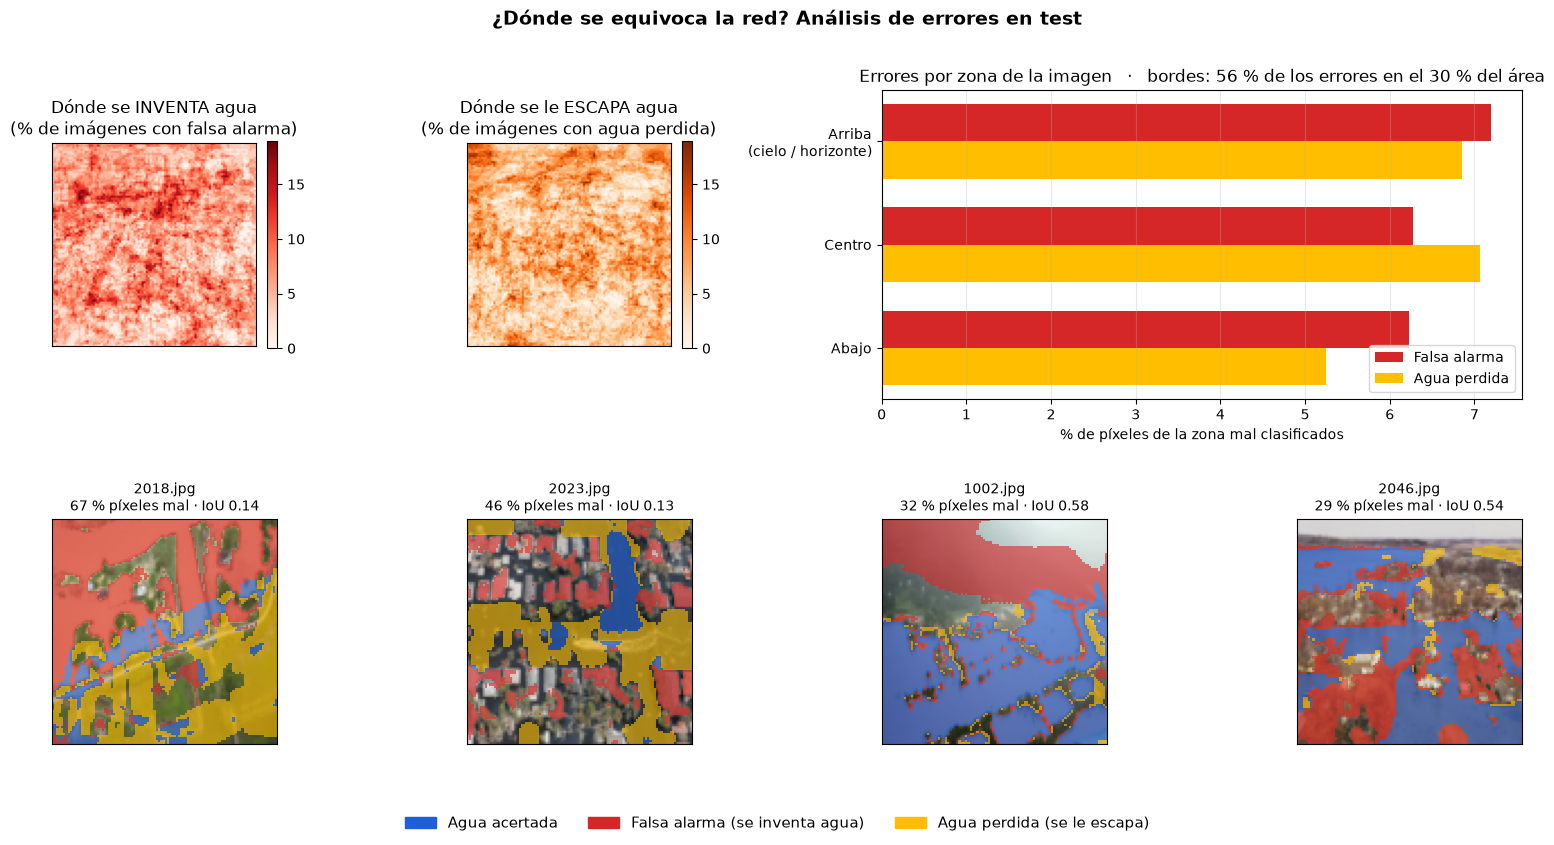

In [17]:
# [MEJORA C3] ¿DÓNDE SE EQUIVOCA LA RED? Análisis de errores píxel a píxel en TEST
# No hace falta volver a entrenar: se usa el modelo final que ya está en memoria (unet).
import matplotlib
import matplotlib.patches
import torch.nn.functional as F

# =====================================================================
# PASO 1. La red predice la máscara de TODAS las imágenes de test
# =====================================================================
unet.eval()
with torch.no_grad():
    pred = torch.cat([
        torch.argmax(unet(imagenes_test[i:i + BATCH_SIZE].to(device)), dim=1).cpu()
        for i in range(0, len(imagenes_test), BATCH_SIZE)
    ])                       # [58, 100, 100] -> 0 = fondo, 1 = agua (lo que dice la red)
real = mascaras_test         # [58, 100, 100] -> 0 = fondo, 1 = agua (la respuesta correcta)

# =====================================================================
# PASO 2. Cada píxel cae en una de estas 4 "cajas"
# =====================================================================
acierto_agua  = (pred == 1) & (real == 1)   # dice agua  y es agua   -> BIEN
acierto_fondo = (pred == 0) & (real == 0)   # dice fondo y es fondo  -> BIEN
falsa_alarma  = (pred == 1) & (real == 0)   # dice agua  y NO lo es  -> ERROR: se "inventa" agua
agua_perdida  = (pred == 0) & (real == 1)   # dice fondo y SÍ es agua -> ERROR: se le escapa agua
error = falsa_alarma | agua_perdida

total_px = real.numel()
n_err = error.sum().item()
n_fa = falsa_alarma.sum().item()
n_ap = agua_perdida.sum().item()

print('1) ¿CUÁNTO FALLA?')
print(f'   Píxeles de test: {total_px:,}  ->  mal clasificados: {n_err:,} ({100 * n_err / total_px:.1f} %)')
print(f'   · Falsas alarmas (ve agua donde no hay): {100 * n_fa / n_err:.0f} % de los errores')
print(f'   · Agua perdida  (no ve agua que sí hay): {100 * n_ap / n_err:.0f} % de los errores')

# =====================================================================
# PASO 3. ¿Falla en los BORDES del agua o en el INTERIOR de las zonas?
# Un píxel es "de borde" si a 2 píxeles o menos hay un cambio agua/fondo en la máscara real.
# Truco: "engordamos" y "adelgazamos" el agua; donde no coinciden, hay borde.
# =====================================================================
real_f = real.float().unsqueeze(1)
engordada = F.max_pool2d(real_f, kernel_size=5, stride=1, padding=2)
adelgazada = -F.max_pool2d(-real_f, kernel_size=5, stride=1, padding=2)
borde = (engordada != adelgazada).squeeze(1)

pct_area_borde = 100 * borde.float().mean().item()
pct_err_borde = 100 * (error & borde).sum().item() / n_err
print('\n2) ¿BORDES O INTERIOR?')
print(f'   Las franjas de borde ocupan el {pct_area_borde:.0f} % de la imagen, '
      f'pero concentran el {pct_err_borde:.0f} % de los errores.')

# =====================================================================
# PASO 4. ¿En qué ZONA de la foto falla más? (arriba suele estar el cielo / horizonte)
# =====================================================================
alto = real.shape[1]
zonas = {
    'Arriba\n(cielo / horizonte)': slice(0, alto // 3),
    'Centro': slice(alto // 3, 2 * alto // 3),
    'Abajo': slice(2 * alto // 3, alto),
}
pct_fa_zona = {z: 100 * falsa_alarma[:, f].float().mean().item() for z, f in zonas.items()}
pct_ap_zona = {z: 100 * agua_perdida[:, f].float().mean().item() for z, f in zonas.items()}

print('\n3) ¿EN QUÉ ZONA DE LA FOTO?  (% de píxeles de esa zona que están mal)')
for z in zonas:
    print(f'   {z.split(chr(10))[0]:<8} -> falsas alarmas {pct_fa_zona[z]:4.1f} % | agua perdida {pct_ap_zona[z]:4.1f} %')

# =====================================================================
# PASO 5. ¿Los errores están repartidos o los concentran unas pocas imágenes?
# =====================================================================
err_por_img = error.flatten(1).sum(dim=1).float()
orden = torch.argsort(err_por_img, descending=True)
n_top = max(1, round(0.10 * len(orden)))                       # el 10 % de imágenes con más fallos
pct_top = 100 * err_por_img[orden[:n_top]].sum().item() / err_por_img.sum().item()
print('\n4) ¿POCAS IMÁGENES O TODAS?')
print(f'   Las {n_top} imágenes con más fallos (el 10 % del test) acumulan el {pct_top:.0f} % de todos los errores.')

df_errores = pd.DataFrame({
    'imagen': nombres_test,
    'pct_pixeles_mal': (100 * err_por_img / real[0].numel()).numpy().round(1),
    'pct_falsa_alarma': (100 * falsa_alarma.flatten(1).float().mean(1)).numpy().round(1),
    'pct_agua_perdida': (100 * agua_perdida.flatten(1).float().mean(1)).numpy().round(1),
}).sort_values('pct_pixeles_mal', ascending=False)
df_errores.to_csv(RUTA_RESULTADOS / 'errores_por_imagen_test.csv', index=False)

# =====================================================================
# PASO 6. Resumen automático en lenguaje llano
# =====================================================================
print('\nRESUMEN')
tipo = 'se inventa agua (falsas alarmas)' if n_fa > n_ap else 'se le escapa agua (agua perdida)'
print(f' · El error más frecuente es que {tipo}.')
if pct_err_borde > 1.5 * pct_area_borde:
    print(f' · Los errores se concentran en los BORDES: {pct_err_borde:.0f} % de los fallos en solo el '
          f'{pct_area_borde:.0f} % de la imagen. La red sabe dónde hay agua, pero dibuja el contorno con poca precisión.')
else:
    print(' · Los errores NO se concentran en los bordes: la red se equivoca en zonas completas.')
zona_fa = max(pct_fa_zona, key=pct_fa_zona.get).split('\n')[0]
print(f' · Las falsas alarmas son más frecuentes en la zona: {zona_fa}.')
if pct_top > 25:
    print(f' · Unas pocas imágenes pesan mucho: el 10 % peor acumula el {pct_top:.0f} % de los errores. '
          f'Conviene mirarlas una a una (ver errores_por_imagen_test.csv).')
else:
    print(f' · Los errores están bastante repartidos entre las imágenes (el 10 % peor solo acumula el {pct_top:.0f} %).')

# =====================================================================
# PASO 7. Figura
#   Fila 1: dónde caen los errores, sumando todas las imágenes de test (mapas de calor) + zonas
#   Fila 2: las 4 imágenes con más errores, con cada píxel coloreado según su "caja"
# =====================================================================
fig = plt.figure(figsize=(15, 8.5))
gs = fig.add_gridspec(2, 4, height_ratios=[1, 1.05])

ax = fig.add_subplot(gs[0, 0])
mapa_fa = 100 * falsa_alarma.float().mean(0)
im = ax.imshow(mapa_fa, cmap='Reds', vmin=0, vmax=max(mapa_fa.max().item(), 1))
ax.set_title('Dónde se INVENTA agua\n(% de imágenes con falsa alarma)')
fig.colorbar(im, ax=ax, fraction=0.046)
ax.set_xticks([]); ax.set_yticks([])

ax = fig.add_subplot(gs[0, 1])
mapa_ap = 100 * agua_perdida.float().mean(0)
im = ax.imshow(mapa_ap, cmap='Oranges', vmin=0, vmax=max(mapa_ap.max().item(), 1))
ax.set_title('Dónde se le ESCAPA agua\n(% de imágenes con agua perdida)')
fig.colorbar(im, ax=ax, fraction=0.046)
ax.set_xticks([]); ax.set_yticks([])

ax = fig.add_subplot(gs[0, 2:])
nombres_zona = list(zonas)
y = np.arange(len(nombres_zona))
ax.barh(y - 0.18, [pct_fa_zona[z] for z in nombres_zona], height=0.36, color='#d62728', label='Falsa alarma')
ax.barh(y + 0.18, [pct_ap_zona[z] for z in nombres_zona], height=0.36, color='#ffbf00', label='Agua perdida')
ax.set_yticks(y, nombres_zona)
ax.invert_yaxis()
ax.set_xlabel('% de píxeles de la zona mal clasificados')
ax.set_title(f'Errores por zona de la imagen   ·   bordes: {pct_err_borde:.0f} % de los errores '
             f'en el {pct_area_borde:.0f} % del área')
ax.legend(loc='lower right')
ax.grid(axis='x', alpha=0.3)

# Colores: azul = agua acertada, rojo = falsa alarma, amarillo = agua perdida (el fondo acertado no se pinta)
colores = matplotlib.colors.ListedColormap(['#1f5fd6', '#d62728', '#ffbf00'])
for col, i in enumerate(orden[:4].tolist()):
    ax = fig.add_subplot(gs[1, col])
    capa = np.full(real[i].shape, np.nan)
    capa[acierto_agua[i].numpy()] = 0
    capa[falsa_alarma[i].numpy()] = 1
    capa[agua_perdida[i].numpy()] = 2
    ax.imshow(imagenes_test[i].permute(1, 2, 0))
    ax.imshow(capa, cmap=colores, vmin=0, vmax=2, alpha=0.6, interpolation='nearest')
    iou_i = calcular_iou(pred[i:i + 1], real[i:i + 1], clase=1)
    ax.set_title(f'{nombres_test[i]}\n{100 * err_por_img[i] / real[i].numel():.0f} % píxeles mal · IoU {iou_i:.2f}',
                 fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])

leyenda = [matplotlib.patches.Patch(color=c, label=t) for c, t in
           [('#1f5fd6', 'Agua acertada'), ('#d62728', 'Falsa alarma (se inventa agua)'),
            ('#ffbf00', 'Agua perdida (se le escapa)')]]
fig.legend(handles=leyenda, loc='lower center', ncol=3, frameon=False, fontsize=11)
fig.suptitle('¿Dónde se equivoca la red? Análisis de errores en test', fontsize=14, fontweight='bold')
fig.tight_layout(rect=(0, 0.04, 1, 0.97))
fig.savefig(RUTA_FIGURAS / 'analisis_errores_test.png', dpi=150, bbox_inches='tight')
plt.show()

## 13. Qué se ha guardado

El entrenamiento deja una carpeta de resultados con:

- `configuracion.json`: parámetros del experimento.
- `metricas_entrenamiento.csv`: pérdida, IoU y tasa de aprendizaje por época.
- `checkpoints/`: pesos del modelo y estado del optimizador por época.
- `predicciones/`: máscaras predichas intermedias en formato `.pt`.
- `figuras/`: visualizaciones del dataset, evolución y comparación final.

Este esquema facilita comparar experimentos y reutilizar el modelo entrenado sin repetir todo el entrenamiento.